In [1]:
# Compact public exports; restore model context for existing figure code only.
def _read_result_csv(path, *args, **kwargs):
    result_table = pd.read_csv(path, *args, **kwargs)
    if "q_value" not in result_table.columns:
        return result_table
    from pathlib import Path
    aliases = {"q_value": "p_value_adjusted", "FDR_significant": "significant_adjusted",
               "predictor": "term", "comparison": "contrast", "grid_id": "hotspot_id",
               "n_grids": "n_hotspots", "test_statistic": "statistic"}
    result_table = result_table.rename(columns={key:current_values for key,current_values in aliases.items() if key in result_table.columns})
    source_path = Path(path)
    info = source_path.parent / (source_path.parent.name + "_run_info.csv")
    if info.exists():
        meta = pd.read_csv(info, dtype=str, keep_default_na=False)
        if set(["section", "item", "field", "value"]).issubset(meta.columns):
            prefix = source_path.name + "::"
            rows = meta[(meta.section == "result_context") & meta.item.str.startswith(prefix)]
            reference_fields = ["estimate", "std_error", "ci_lower", "ci_upper", "df", "statistic",
                                "p_value", "p_value_adjusted", "significant_adjusted", "n_observations", "n_participants"]
            promoted60 = source_path.name.endswith("Sensitivity_60s.csv") and rows.field.str.startswith("reference10s__").any()
            live60 = set()
            if promoted60:
                for field in reference_fields:
                    live60.add(field + "_60s")
                    result_table[field + "_60s"] = result_table[field] if field in result_table.columns else None
                    if field in result_table.columns:
                        result_table = result_table.drop(columns=[field])
            for field, group in rows.groupby("field", sort=False):
                if field in live60:
                    continue
                if field not in result_table.columns:
                    result_table[field] = None
                for item, value in zip(group.item, group.value):
                    index = int(item.rsplit("::", 1)[1]) - 1
                    if 0 <= index < len(result_table):
                        result_table.at[index, field] = value
            if promoted60:
                for field in reference_fields:
                    reference = "reference10s__" + field
                    result_table[field] = result_table[reference] if reference in result_table.columns else None
                    if reference in result_table.columns:
                        result_table = result_table.drop(columns=[reference])
    # Match pandas' original inference of numeric and Boolean fields.
    return pd.read_csv(io.StringIO(result_table.to_csv(index=False)), *args, **kwargs)

import io
import sys, os, re, hashlib, subprocess, textwrap
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from PIL import Image
Image.MAX_IMAGE_PIXELS = None

from pathlib import Path

# ---- paths ----
# ROOT = project folder "Pranav Paper3_Final". The notebook lives in ROOT\scripts, so ROOT is the parent of the
# notebook's folder; the absolute PC path is the fallback.
_FALLBACK_ROOT = Path(r"C:\Users\sanga\Desktop\Pranav Paper3_Final")
_MERGED_REL = Path("output") / "merged_all_11participants_8min.csv"
ROOT = next((candidate_root for candidate_root in (Path.cwd().parent, Path.cwd(), _FALLBACK_ROOT) if (candidate_root / _MERGED_REL).exists()), _FALLBACK_ROOT)
OUT = ROOT / "Figures"
os.makedirs(OUT, exist_ok=True)
print("ROOT =", ROOT)
print("OUT  =", OUT)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5, "axes.linewidth": 0.6,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "savefig.dpi": 300})

# ---- study constants (Paper3_common.R) ----
PARTICIPANTS = ["P4", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15", "P16", "P17"]
PHASES = ["BikeU", "WalkU", "BikeG", "WalkG"]
PHASE_COL = {"BikeU": "#a50f15", "WalkU": "#f08a5d", "BikeG": "#006d2c", "WalkG": "#74c476"}
PHASE_LAB = {"BikeU": "Bike-Urban", "WalkU": "Walk-Urban", "BikeG": "Bike-Green", "WalkG": "Walk-Green"}
OUTCOMES = ["empatica_heart_rate", "empatica_eda_tonic", "empatica_eda_phasic", "empatica_skin_temperature",
    "empatica_hrv_td_sdnn", "empatica_hrv_td_rmssd", "empatica_hrv_fd_lf", "empatica_hrv_fd_hf",
    "empatica_hrv_fd_lf_hf_ratio", "empatica_hrv_fd_lfnu", "empatica_hrv_fd_hfnu", "empatica_hrv_fd_vlf",
    "empatica_hrv_fd_total_power",
    "eyetracker_pupil_diameter_avg", "eyetracker_pupil_change_rate", "eyetracker_blink_duration_s",
    "eyetracker_fixation_duration_s", "eyetracker_fixation_rate", "eyetracker_saccade_duration_s",
    "eyetracker_saccade_amplitude", "eyetracker_saccade_peak_velocity", "eyetracker_gaze_velocity",
    "eyetracker_gaze_dispersion", "eyetracker_distance_from_center", "eyetracker_gaze_centrality",
    "eyetracker_eyelid_aperture_avg"]
HRV_FD = OUTCOMES[6:13]
# clean_labels (H1_H3_core.R) without device prefix
LAB = {"empatica_heart_rate": "Heart rate (bpm)", "empatica_eda_tonic": "EDA tonic (SCL)", "empatica_eda_phasic": "EDA phasic (SCR)",
    "empatica_skin_temperature": "Skin temperature (°C)", "empatica_hrv_td_sdnn": "HRV SDNN (ms)", "empatica_hrv_td_rmssd": "HRV RMSSD (ms)",
    "empatica_hrv_fd_lf": "HRV LF power (ms²)", "empatica_hrv_fd_hf": "HRV HF power (ms²)", "empatica_hrv_fd_lf_hf_ratio": "HRV LF/HF ratio",
    "empatica_hrv_fd_lfnu": "HRV LF (nu)", "empatica_hrv_fd_hfnu": "HRV HF (nu)", "empatica_hrv_fd_vlf": "HRV VLF power (ms²)",
    "empatica_hrv_fd_total_power": "HRV total power (ms²)", "eyetracker_pupil_diameter_avg": "Pupil diameter (mm)",
    "eyetracker_pupil_change_rate": "Pupil change rate", "eyetracker_blink_duration_s": "Blink duration (s)",
    "eyetracker_fixation_duration_s": "Fixation duration (s)", "eyetracker_fixation_rate": "Fixation rate (/s)",
    "eyetracker_saccade_duration_s": "Saccade duration (s)", "eyetracker_saccade_amplitude": "Saccade amplitude (°)",
    "eyetracker_saccade_peak_velocity": "Saccade peak velocity (°/s)", "eyetracker_gaze_velocity": "Gaze velocity (°/s)",
    "eyetracker_gaze_dispersion": "Gaze dispersion", "eyetracker_distance_from_center": "Gaze distance from centre (px)",
    "eyetracker_gaze_centrality": "Gaze centrality", "eyetracker_eyelid_aperture_avg": "Eyelid aperture (mm)"}
SURVEYS = ["questionnaire_current_comfort_1_7", "questionnaire_pleasantness_1_5", "questionnaire_stai6_mean_1_5", "questionnaire_prs11_total_mean_1_5"]
SURVEY_LAB = {"questionnaire_current_comfort_1_7": "General comfort (1–7)", "questionnaire_pleasantness_1_5": "Pleasantness (1–5)",
    "questionnaire_stai6_mean_1_5": "State anxiety STAI-6 (1–5)", "questionnaire_prs11_total_mean_1_5": "Restorativeness PRS-11 (1–5)"}

USED = set()   # input files read, for provenance printout

RESULTS = ROOT / "output" / "statistical_analysis" / "results"

def src(rel, pc_rel):
    """pc_rel is relative to ROOT. Statistical tables must sit in the current results folder, never under archive."""
    candidate_path = ROOT.joinpath(*pc_rel.split("\\"))
    if not candidate_path.exists():
        raise FileNotFoundError(candidate_path)
    resolved = candidate_path.resolve()
    if "results" in [part.lower() for part in resolved.parts]:
        if "archive" in [part.lower() for part in resolved.parts]:
            raise RuntimeError("archived result refused: " + str(resolved))
        try:
            resolved.relative_to(RESULTS.resolve())
        except ValueError:
            raise RuntimeError("result is outside the current results folder: " + str(resolved))
    USED.add(str(resolved))
    return str(resolved)

# H1_H3_phaseavg combined outputs (output reduction 1 Nov 2026): return the rows of the former H1_Contrasts.csv /
# H3_Contrasts.csv / H2_Physio_Psycho_Concordance.csv, with the shared column names of Paper3_output_names.R.
def _reparse(t):   # filter on text, then parse like the former single-table CSV (same dtypes)
    import io
    return _read_result_csv(io.StringIO(t.to_csv(index=False)))

COMP_MAP = {
    "BikeG - BikeU": ("H1", "H1.1", "BikeU_BikeG"),
    "WalkG - WalkU": ("H1", "H1.2", "WalkU_WalkG"),
    "WalkU - BikeU": ("H3", "H3.1", "BikeU_WalkU"),
    "WalkG - BikeG": ("H3", "H3.2", "BikeG_WalkG"),
}
def h1h3_contrasts(hyp):
    results_table = _read_result_csv(src("res/H1_H3_Contrasts.csv", r"output\statistical_analysis\results\H1_H3_phaseavg\H1_H3_Contrasts.csv"), dtype=str, keep_default_na=False)
    results_table["hypothesis"] = results_table.context.str.extract(r"hypothesis=([^;]+)", expand=False)
    results_table["outcome_type"] = results_table.context.str.extract(r"outcome_type=([^;]+)", expand=False)
    results_table = results_table[(results_table.hypothesis == hyp) & (results_table.outcome_type == "Physiological")].copy()
    results_table = results_table[results_table.scale.astype(str).str.startswith("normalization=Primary")]
    sub, con = [], []
    for cmp in results_table.contrast.astype(str):
        meta = COMP_MAP.get(cmp, (None, None, None))
        sub.append(meta[1]); con.append(meta[2])
    results_table["sub_hypothesis"] = sub
    results_table["contrast"] = con
    phase_ids = results_table["contrast"].astype(str).str.split("_", n=1, expand=True)
    results_table["reference_phase_id"] = phase_ids[0]
    results_table["comparison_phase_id"] = phase_ids[1]
    results_table["normalization"] = results_table.scale.astype(str)
    results_table["adjustment_family_size"] = 26
    results_table["smd_ci_lower"] = pd.to_numeric(results_table.smd_ci_lower, errors="coerce")
    results_table["smd_ci_upper"] = pd.to_numeric(results_table.smd_ci_upper, errors="coerce")
    results_table["smd"] = pd.to_numeric(results_table.smd, errors="coerce")
    return _reparse(results_table.drop(columns=["outcome_type"], errors="ignore"))

def h2_concordance():
    results_table = _read_result_csv(src("res/H2_Concordance.csv", r"output\statistical_analysis\results\H1_H3_phaseavg\H2_Concordance.csv"), dtype=str, keep_default_na=False)
    if "test" in results_table.columns:
        results_table = results_table[results_table.test == "H2_rmcorr_physio_psycho"]
    else:
        ctx = results_table.context.fillna("").astype(str)
        if ctx.str.contains("H2_rmcorr", na=False).any():
            results_table = results_table[ctx.str.contains("H2_rmcorr", na=False)]
        else:
            results_table = results_table[ctx.str.strip() == ""]
    drop = [c for c in ("test", "mode") if c in results_table.columns]
    return _reparse(results_table.drop(columns=drop))

def md5(file_path):
    digest = hashlib.md5()
    with open(file_path, "rb") as input_stream:
        for b in iter(lambda: input_stream.read(1 << 20), b""): digest.update(b)
    return digest.hexdigest()

# ---------------- data ----------------
_cache = {}
def merged():
    if "m" in _cache: return _cache["m"]
    input_path = src("merged_all_11participants_8min.csv", r"output\merged_all_11participants_8min.csv")
    print("merged", md5(input_path)[:8], "rows pending filter")
    epochs = _read_result_csv(input_path, low_memory=False)
    epochs = epochs[epochs.ParticipantID.isin(PARTICIPANTS) & epochs.PhaseID.isin(PHASES)].copy()
    epochs["Datetime"] = pd.to_datetime(epochs["Datetime"])        # clock time as stored in the CSV (time zone not documented in the scripts)
    epochs = epochs.sort_values(["ParticipantID", "PhaseID", "Datetime"])
    epochs["t_sec"] = epochs.groupby(["ParticipantID", "PhaseID"]).Datetime.transform(lambda x: (x - x.min()).dt.total_seconds())
    # bilateral / two-sensor averages exactly as H5_combined_core.R average_sources (rowMeans, na.rm=TRUE)
    avg = {"atmo_pm2.5_avg": ["atmo_lys_atmotube_left__atmotube_pm2.5", "atmo_lys_atmotube_right__atmotube_pm2.5"],
           "atmo_pm1_avg": ["atmo_lys_atmotube_left__atmotube_pm1", "atmo_lys_atmotube_right__atmotube_pm1"],
           "atmo_pm10_avg": ["atmo_lys_atmotube_left__atmotube_pm10", "atmo_lys_atmotube_right__atmotube_pm10"],
           "lys_lux_avg": ["atmo_lys_LYS1__lys_lux", "atmo_lys_LYS2__lys_lux"],
           "lys_kelvin_avg": ["atmo_lys_LYS1__lys_kelvin", "atmo_lys_LYS2__lys_kelvin"]}
    for key, current_values in avg.items(): epochs[key] = epochs[current_values].mean(axis=1, skipna=True)
    assert len(epochs) == 2112 and (epochs.groupby(["ParticipantID", "PhaseID"]).size() == 48).all()
    _cache["m"] = epochs; return epochs

def ln_outcomes():
    normalization_path = src("res/Normalization_H1toH4_all_parameters.csv",
            r"output\statistical_analysis\Normalization & Parameter Screening\Normalization\Normalization_H1toH4_all_parameters.csv")
    normalization_table = _read_result_csv(normalization_path).set_index("column_name")
    tr = normalization_table.loc[OUTCOMES, "transformation_in_models"]
    assert set(tr) <= {"Natural log", "No transformation"}
    return [outcome for outcome in OUTCOMES if tr[outcome] == "Natural log"]

def analysis_units(epochs):
    """Row-level ln(x) (x<=0 -> NA) for 'Natural log' outcomes (paper3_outcome_natural_log), others native."""
    analysis_epochs = epochs.copy()
    for outcome in ln_outcomes():
        x = analysis_epochs[outcome].astype(float); analysis_epochs[outcome] = np.where(np.isfinite(x) & (x > 0), np.log(x.where(x > 0)), np.nan)
    return analysis_epochs

def phase_means(epochs, cols):
    return epochs.groupby(["ParticipantID", "PhaseID"], as_index=False)[cols].mean()

def ulab(outcome):
    return ("ln " + LAB[outcome]) if outcome in ln_outcomes() else LAB[outcome]

# ---------------- helpers ----------------
def panel_label(ax, s, dx=-0.02, dy=0.01, fig=None, size=10):
    fig = fig or ax.figure
    bb = ax.get_position()
    fig.text(bb.x0 + dx, bb.y1 + dy, s, fontsize=size, fontweight="bold", ha="right", va="bottom")

def img_axes(ax, path, title=None):
    im = Image.open(path)
    im.draft("RGB", (1100, 1100))
    im = im.convert("RGB")
    im.thumbnail((1100, 1100))
    ax.imshow(np.asarray(im)); ax.set_axis_off()
    if title: ax.set_title(title, loc="left", fontsize=8)
    return im.size

def save(fig, name):
    svg = OUT / (name + ".svg")
    png = OUT / (name + ".png")
    fig.savefig(svg, format="svg", facecolor="white", bbox_inches="tight")
    fig.savefig(png, format="png", dpi=300, facecolor="white", bbox_inches="tight")
    plt.close(fig)
    print("saved", svg, "and", png)
    try:
        from IPython.display import display, SVG
        display(SVG(filename=str(svg)))
    except Exception:
        pass

def bh(p):
    p = np.asarray(p, float); out = np.full(p.shape, np.nan); ok = np.isfinite(p); pp = p[ok]; n = len(pp)
    if n == 0: return out
    outcome = np.argsort(pp); q = pp[outcome] * n / np.arange(1, n + 1); q = np.minimum.accumulate(q[::-1])[::-1]
    r = np.empty(n); r[outcome] = np.minimum(q, 1); out[ok] = r; return out

def phase_legend(ax, loc="best", ncol=1, **kw):
    legend_handles = [Line2D([], [], marker="o", ls="", color=PHASE_COL[phase], label=PHASE_LAB[phase] + f" ({phase})", markersize=4.5) for phase in PHASES]
    return ax.legend(handles=legend_handles, loc=loc, ncol=ncol, frameon=False, **kw)

def strip_box(ax, data_by_phase, pos=None, width=0.6, log=False):
    pos = pos or list(range(len(PHASES)))
    vals = [np.asarray(current_values, float)[np.isfinite(np.asarray(current_values, float))] for current_values in data_by_phase]
    bp = ax.boxplot(vals, positions=pos, widths=width, patch_artist=True, showfliers=False, whis=(5, 95),
                    medianprops=dict(color="black", lw=0.8), boxprops=dict(lw=0.5), whiskerprops=dict(lw=0.5), capprops=dict(lw=0.5))
    for b, local_phase in zip(bp["boxes"], PHASES): b.set_facecolor(PHASE_COL[local_phase]); b.set_alpha(0.45)
    return bp


ROOT = C:\Users\sanga\Desktop\Pranav Paper3_Final
OUT  = C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures


In [2]:
# Figure 3 — exposures by phase (10 s epochs) + UTCI × dBA plane (participant phase means)
EXPOSURES = [("ucm_UTCI", "UTCI (°C)", False), ("ucm_AIR_T_mid", "Air temperature (°C)", False),
             ("ucm_MRT", "MRT (°C)", False), ("ucm_SND_dBA", "Sound level (dBA)", False),
             ("atmo_pm2.5_avg", "PM2.5 (µg/m³)", False), ("lys_lux_avg", "Illuminance (lux)", True),
             ("SVF", "Sky view factor", False), ("gvi_50m", "Green view index (%)", False)]

def fig3():
    plot_data = merged()
    fig = plt.figure(figsize=(7.2, 4.4))
    gs = gridspec.GridSpec(2, 4, figure=fig, left=0.075, right=0.985, top=0.92, bottom=0.12, hspace=0.45, wspace=0.45)
    letters = "abcdefghij"
    for index, (col, lab, logy) in enumerate(EXPOSURES):
        ax = fig.add_subplot(gs[index // 4, index % 4])
        vals = [plot_data.loc[plot_data.PhaseID == phase, col].astype(float).values for phase in PHASES]
        if logy: vals = [np.where(current_values > 0, current_values, np.nan) for current_values in vals]
        strip_box(ax, vals)
        if logy: ax.set_yscale("log")
        ax.set_xticks(range(4)); ax.set_xticklabels(PHASES, rotation=0)
        ax.set_title(lab, fontsize=7, loc="left")
        n_valid = int(np.isfinite(np.concatenate(vals)).sum())
        ax.text(0.99, 0.99, f"n={n_valid}", transform=ax.transAxes, ha="right", va="top", fontsize=5.5, color="#555555")
        panel_label(ax, letters[index], dx=-0.035)
    fig.text(0.5, 0.02, "Boxes are 10 s epochs (median, interquartile range, whiskers at the 5th and 95th percentiles). No phase means are plotted.",
             ha="center", fontsize=6, color="#444444")
    save(fig, "Figure5_exposures_by_phase")

fig3()


merged a3c4f938 rows pending filter
saved C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures\Figure5_exposures_by_phase.svg
<IPython.core.display.SVG object>


In [ ]:
# Figure 4 â€” H1 + H3 forest plot (paired SMD, Bonett 2008; filled = primary-LMM BH q < 0.05)
# H1 and H3 forests. Each contrast is phase mean, then 10 s. Shared axis is -5 to 5 SD.
def _fdr_hit(value):
    if pd.isna(value):
        return False
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    return str(value).strip().upper() == "TRUE"

def _q_label(q):
    q = float(q)
    return f"q={q:.3f}" if q >= 0.001 else f"q={q:.0e}"

def _load_10s_phase_level():
    raw = _read_result_csv(src(
        "res/H1_H3_10s.csv",
        r"output\statistical_analysis\results\H1_H3_timeseries\H1_H3_Planned_Contrasts_10s.csv",
    ))
    raw["hypothesis_id"] = raw.context.str.extract(r"hypothesis=([^;]+)", expand=False)
    t = raw[(raw.effect_type == "phase_level") & raw.hypothesis_id.isin(["H1", "H3"])].copy()
    t["std_error"] = pd.to_numeric(t.std_error, errors="coerce")
    t["estimate"] = pd.to_numeric(t.estimate, errors="coerce")
    t["p_value_adjusted"] = pd.to_numeric(t.p_value_adjusted, errors="coerce")
    t = t[np.isfinite(t.estimate) & np.isfinite(t.std_error) & (t.std_error < 10)]
    t["lo"] = t.estimate - 1.96 * t.std_error
    t["hi"] = t.estimate + 1.96 * t.std_error
    return t

XLIM = (-5, 5)

def _forest_panel(ax, series, selector, sub, con, xcol, locol, hicol, title, col, ypos, show_y):
    s = selector(series, sub, con)
    ax.axvline(0, color="#777777", lw=0.6, ls="--")
    ax.axhspan(12.5, 14.5, color="white")
    for outcome in OUTCOMES:
        r = s.loc[outcome]
        y = ypos[outcome]
        if not np.isfinite(r[xcol]):
            continue
        sig = _fdr_hit(r.significant_adjusted)
        lo, hi = float(r[locol]), float(r[hicol])
        x = float(r[xcol])
        ax.plot([lo, hi], [y, y], color=col, lw=0.9, clip_on=True)
        ax.plot(x, y, marker="o", ms=4.2, mfc=col if sig else "white", mec=col, mew=0.9, clip_on=True)
        if sig and np.isfinite(r.p_value_adjusted):
            if x < -3.2:
                ha = "left"
            elif x > 3.2:
                ha = "right"
            else:
                ha = "center"
            ax.text(x, y - 0.55, _q_label(r.p_value_adjusted), ha=ha, va="center",
                    fontsize=4.2, color="#222222", clip_on=False)
    ax.set_ylim(27.7, -1.35)
    ax.set_xlim(*XLIM)
    ax.set_xticks(range(XLIM[0], XLIM[1] + 1))
    ax.set_xticklabels([str(tick) for tick in range(XLIM[0], XLIM[1] + 1)])
    ax.set_yticks([ypos[outcome] for outcome in OUTCOMES])
    ax.set_yticklabels([ulab(outcome) for outcome in OUTCOMES] if show_y else [])
    ax.tick_params(axis="y", length=0 if not show_y else 2)
    ax.set_title(title, fontsize=7, color="black")
    ax.set_xlabel("Difference (SD)")
    ax.grid(axis="x", color="#eeeeee", lw=0.5)
    ax.set_axisbelow(True)
    ax.axhline(13.0, color="#bbbbbb", lw=0.5)

def _draw_hypothesis(name, panels, phase, ten):
    ypos = {outcome: index + (1.0 if index >= 13 else 0) for index, outcome in enumerate(OUTCOMES)}
    fig = plt.figure(figsize=(13.6, 5.8))
    gs = gridspec.GridSpec(1, 4, figure=fig, left=0.12, right=0.88, top=0.88, bottom=0.12, wspace=0.62)
    def phase_selector(series, sub, con):
        return series[(series.sub_hypothesis == sub) & (series.contrast == con)].set_index("outcome").reindex(OUTCOMES)
    def ten_selector(series, sub, con):
        comp = {"BikeU_BikeG": "BikeG - BikeU", "WalkU_WalkG": "WalkG - WalkU", "BikeU_WalkU": "WalkU - BikeU", "BikeG_WalkG": "WalkG - BikeG"}
        hyp = sub.split(".")[0]
        return series[(series.hypothesis_id == hyp) & (series.contrast == comp[con])].drop_duplicates("outcome").set_index("outcome").reindex(OUTCOMES)
    for key, (sub, con, lab, ttl, col) in enumerate(panels):
        phase_ax = fig.add_subplot(gs[0, key * 2])
        ten_ax = fig.add_subplot(gs[0, key * 2 + 1])
        _forest_panel(phase_ax, phase, phase_selector, sub, con, "smd", "smd_ci_lower", "smd_ci_upper", f"{sub}: {lab}\n{ttl}\nPhase mean", col, ypos, key == 0)
        _forest_panel(ten_ax, ten, ten_selector, sub, con, "estimate", "lo", "hi", f"{sub}: {lab}\n{ttl}\n10 s", col, ypos, False)
        panel_label(phase_ax, "abcd"[key * 2], dx=0.0, dy=0.035)
        panel_label(ten_ax, "abcd"[key * 2 + 1], dx=0.0, dy=0.035)
        if key == 0:
            for (y0, y1, txt) in [(0, 12, "Empatica (13)"), (14, 26, "Eye tracker (13)")]:
                phase_ax.annotate("", xy=(-1.22, y0 - 0.3), xytext=(-1.22, y1 + 0.3), xycoords=phase_ax.get_yaxis_transform(), textcoords=phase_ax.get_yaxis_transform(),
                            arrowprops=dict(arrowstyle="-", lw=0.8, color="#333333"), annotation_clip=False)
                phase_ax.text(-1.28, (y0 + y1) / 2, txt, transform=phase_ax.get_yaxis_transform(), rotation=90, va="center", ha="center", fontsize=7, fontweight="bold")
    leg = [Line2D([], [], marker="o", ls="", mfc="black", mec="black", ms=4, label="BH-FDR q < 0.05 (family = contrast \u00d7 26 outcomes)"),
           Line2D([], [], marker="o", ls="", mfc="white", mec="black", ms=4, label="q \u2265 0.05")]
    fig.legend(handles=leg, loc="lower center", ncol=2, frameon=False, fontsize=6.5, bbox_to_anchor=(0.55, 0.0))
    save(fig, name)

def fig_h1_h3():
    phase = pd.concat([h1h3_contrasts("H1"), h1h3_contrasts("H3")])
    phase = phase[phase.normalization.str.contains("Primary", na=False)]
    ten = _load_10s_phase_level()
    h1 = [("H1.1", "BikeU_BikeG", "BikeG \u2212 BikeU", "Green \u2212 urban, bike", PHASE_COL["BikeG"]),
          ("H1.2", "WalkU_WalkG", "WalkG \u2212 WalkU", "Green \u2212 urban, walk", PHASE_COL["WalkG"])]
    h3 = [("H3.1", "BikeU_WalkU", "WalkU \u2212 BikeU", "Walk \u2212 bike, urban", "#b2182b"),
          ("H3.2", "BikeG_WalkG", "WalkG \u2212 BikeG", "Walk \u2212 bike, green", "#f08a5d")]
    _draw_hypothesis("Figure6_H1_forest", h1, phase, ten)
    _draw_hypothesis("Figure7_H3_forest", h3, phase, ten)

fig_h1_h3()


In [4]:
# Figure 3 — H2 rmcorr heatmap (all questionnaire × physiological outcomes)
def fig5():
    h2 = h2_concordance()
    assert len(h2) > 0, "H2 concordance table is empty after filtering pooled rows"
    surveys = sorted(c for c in h2.outcome.drop_duplicates() if str(c).startswith("questionnaire"))
    R = h2.pivot(index="outcome", columns="term", values="correlation").reindex(index=surveys, columns=OUTCOMES)
    Q = h2.pivot(index="outcome", columns="term", values="p_value_adjusted").reindex(index=surveys, columns=OUTCOMES)

    def qlab(col):
        if col in SURVEY_LAB:
            label = SURVEY_LAB[col]
        else:
            label = col.replace("questionnaire_", "").replace("_mean_1_5", "").replace("_1_7", "").replace("_1_5", "").replace("_rev", "").replace("_", " ")
        if "_rev" in str(col):
            label = label + " (reversed)"
        return label

    n_surv = len(surveys)
    fig_h = max(7.2, 0.26 * n_surv + 2.6)
    fig = plt.figure(figsize=(7.4, fig_h))
    ax = fig.add_axes([0.30, 0.32, 0.54, 0.62])
    im = ax.imshow(R.values, cmap=plt.get_cmap("RdBu_r"), vmin=-0.8, vmax=0.8, aspect="auto")
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            v = R.values[i, j]
            q = Q.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}".replace("0.", ".").replace("-.", "−."), ha="center", va="center", fontsize=4.6,
                        color="white" if abs(v) > 0.5 else "black", fontweight="bold" if np.isfinite(q) and q < 0.05 else "normal")
            if np.isfinite(q) and q < 0.05:
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="black", lw=1.3))
    ax.set_yticks(range(n_surv))
    ax.set_yticklabels([qlab(s) for s in surveys], fontsize=6.5)
    ax.set_xticks(range(26))
    ax.set_xticklabels([ulab(o) for o in OUTCOMES], fontsize=5.6)
    ax.tick_params(axis="x", length=0, pad=1)
    plt.setp(ax.get_xticklabels(), rotation=90, ha="center", va="top")
    ax.tick_params(axis="y", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.axvline(12.5, color="black", lw=0.8)
    cax = fig.add_axes([0.86, 0.32, 0.015, 0.62])
    cb = fig.colorbar(im, cax=cax)
    cb.set_label("Repeated-measures correlation r", fontsize=6)
    cb.ax.tick_params(labelsize=5.5)
    fig.text(0.30, 0.02,
             "Black box / bold = BH-FDR q < 0.05. Pooled rmcorr on 44 participant × phase means (not 10 s epochs). Vertical line: Empatica | eye tracker.",
             fontsize=5.8, color="#333333")
    panel_label(ax, "a", dx=-0.12, dy=0.02)
    save(fig, "Figure8_H2_rmcorr")

fig5()


saved C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures\Figure8_H2_rmcorr.svg
<IPython.core.display.SVG object>


In [ ]:
# H4 — updated approach only: Y ~ dBA_z + UTCI_z + (1|participant)
# Walking bouts only. No cycling extension. No tram. No product.
H4_CSV = src(
    "res/H4_updated_merged_tests.csv",
    r"output\statistical_analysis\results\H4_updated_merged_test\H4_updated_merged_tests.csv",
)
H4_COL = {"dba_z": "#1b4f72", "utci_z": "#b03a2e"}
H4_TERM_LAB = {"dba_z": "dBA", "utci_z": "UTCI"}
H4_OUT_LAB = {
    "thermal_comfort": "Thermal comfort",
    "acoustic_comfort": "Acoustic comfort",
    "overall_comfort": "Overall comfort",
}
H4_OUTCOMES = ["thermal_comfort", "acoustic_comfort", "overall_comfort"]

def _h4_table():
    t = pd.read_csv(H4_CSV)
    t = t[t.block == "measured_joint"].copy()
    for col in ("estimate", "p", "ci_lower", "ci_upper"):
        t[col] = pd.to_numeric(t[col], errors="coerce")
    return t

def _h4_panel(ax, table, scope, title, show_y):
    s = table[table.scope == scope]
    ax.axvline(0, color="#777777", lw=0.6, ls="--")
    ax.grid(axis="x", color="#eeeeee", lw=0.5)
    ax.set_axisbelow(True)
    ypos = {oc: 2 - i for i, oc in enumerate(H4_OUTCOMES)}
    for oc in H4_OUTCOMES:
        y0 = ypos[oc]
        for term, dy in (("dba_z", 0.18), ("utci_z", -0.18)):
            r = s[(s.outcome == oc) & (s.term == term)].iloc[0]
            x, lo, hi, p = float(r.estimate), float(r.ci_lower), float(r.ci_upper), float(r.p)
            col = H4_COL[term]
            y = y0 + dy
            ax.plot([lo, hi], [y, y], color=col, lw=1.0, solid_capstyle="butt")
            sig = p < 0.05
            ax.plot(x, y, marker="o", ms=5.2, mfc=col if sig else "white", mec=col, mew=0.9, zorder=3)
            if sig:
                ax.text(x, y - 0.28, f"p={p:.3f}", ha="center", va="top", fontsize=5.2, color="#222222")
    ax.set_yticks([ypos[oc] for oc in H4_OUTCOMES])
    ax.set_yticklabels([H4_OUT_LAB[oc] for oc in H4_OUTCOMES] if show_y else [])
    ax.tick_params(axis="y", length=0 if not show_y else 2)
    ax.set_ylim(-0.7, 2.7)
    ax.set_xlim(-1.35, 1.05)
    ax.set_title(title, fontsize=8)
    ax.set_xlabel("Coefficient per 1 SD")

def fig_h4():
    table = _h4_table()
    fig, ax = plt.subplots(figsize=(3.8, 3.15))
    fig.subplots_adjust(left=0.36, right=0.96, top=0.88, bottom=0.22)
    _h4_panel(ax, table, "walk", "Walking (22 bouts)", True)
    legend_handles = [
        Line2D([], [], marker="o", ls="-", color=H4_COL["dba_z"], mfc=H4_COL["dba_z"], label="dBA  p < 0.05", ms=5),
        Line2D([], [], marker="o", ls="-", color=H4_COL["dba_z"], mfc="white", label="dBA  p ≥ 0.05", ms=5),
        Line2D([], [], marker="o", ls="-", color=H4_COL["utci_z"], mfc=H4_COL["utci_z"], label="UTCI  p < 0.05", ms=5),
        Line2D([], [], marker="o", ls="-", color=H4_COL["utci_z"], mfc="white", label="UTCI  p ≥ 0.05", ms=5),
    ]
    fig.legend(handles=legend_handles, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.66, -0.02))
    panel_label(ax, "a")
    save(fig, "H4_coefficients")
    fig, ax = plt.subplots(figsize=(3.6, 3.15))
    fig.subplots_adjust(left=0.38, right=0.96, top=0.88, bottom=0.16)
    _h4_panel(ax, table, "walk", "Walking (22 bouts)", True)
    save(fig, "H4_walk")

fig_h4()


In [5]:
# Figure 4 - sound composition by phase (10 s epochs)
# (a) dBA per epoch with participant means, (b) octave-band profile, (c) YAMNet category mean proportion,
# (d) YAMNet category mean score with 0.20 threshold, (e) example participant 10 s dBA time series.
SND_CATS = [("wind", "Wind"), ("rural_natural", "Rural/Natural"), ("vehicle", "Vehicle"),
            ("urban_manmade_neutral", "Urban neutral"), ("urban_manmade_positive", "Urban positive"),
            ("urban_manmade_negative", "Urban negative"), ("mechanisms", "Mechanisms"), ("unidentify", "Unidentified")]

def fig4_sound():
    snd = merged()
    snd = snd.assign(t_min=snd["t_sec"] / 60.0)
    dba = "ucm_SND_dBA"
    prop_cols = [(k + "_proportion", lab) for k, lab in SND_CATS if k + "_proportion" in snd.columns]
    score_cols = [(k + "_score", lab) for k, lab in SND_CATS if k + "_score" in snd.columns]
    oc = [c for c in snd.columns if c.startswith("octave_proportion_")]
    n_pid = {ph: snd.loc[snd.PhaseID == ph, "ParticipantID"].nunique() for ph in PHASES}

    def color_ticks(ax):
        for tl, ph in zip(ax.get_xticklabels(), PHASES):
            tl.set_color(PHASE_COL[ph])

    fig, axd = plt.subplot_mosaic([["a", "b"], ["c", "d"], ["e", "e"]], figsize=(7.2, 8.6), height_ratios=[1, 1.05, 0.85])
    fig.subplots_adjust(left=0.13, right=0.98, top=0.955, bottom=0.085, hspace=0.62, wspace=0.5)

    # (a) dBA distribution per phase + participant phase means
    ax = axd["a"]
    vals = [snd.loc[snd.PhaseID == ph, dba].astype(float).dropna().values for ph in PHASES]
    vp = ax.violinplot(vals, positions=range(4), widths=0.8, showextrema=False)
    for b, ph in zip(vp["bodies"], PHASES):
        b.set_facecolor(PHASE_COL[ph]); b.set_alpha(0.3); b.set_edgecolor("none")
    bp = strip_box(ax, vals, width=0.25)
    for b in bp["boxes"]:
        b.set_alpha(0.55)
    pm = snd.groupby(["ParticipantID", "PhaseID"])[dba].mean().reset_index()
    rng = np.random.default_rng(1)
    for i, ph in enumerate(PHASES):
        y = pm.loc[pm.PhaseID == ph, dba].values
        ax.scatter(i + 0.22 + rng.uniform(-0.04, 0.04, len(y)), y, s=7, color=PHASE_COL[ph], edgecolor="black", lw=0.3, zorder=3)
        ax.text(i, 1.01, f"mean {np.nanmean(vals[i]):.1f}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=5.4)
    ax.set_xticks(range(4)); ax.set_xticklabels([f"{ph}\n(n={n_pid[ph]})" for ph in PHASES]); color_ticks(ax)
    ax.set_ylabel("Sound level (dBA)")
    ax.set_title("Loudness and dBA", fontsize=6.6, loc="left", pad=10)

    # (b) octave-band profile
    ax = axd["b"]
    fc = [float(c.replace("octave_proportion_", "").replace("_Hz", "").replace("_", ".")) for c in oc]
    for ph in PHASES:
        x = snd.loc[snd.PhaseID == ph, oc]
        ax.plot(fc, x.mean().values * 100, "-o", color=PHASE_COL[ph], ms=2.5, lw=1, label=ph)
    ax.set_xscale("log"); ax.set_xticks(fc)
    ax.set_xticklabels([("%g" % f) if f < 1000 else ("%gk" % (f / 1000)) for f in fc], fontsize=5.6)
    ax.minorticks_off(); ax.set_xlabel("Octave-band centre frequency (Hz)"); ax.set_ylabel("Mean energy share (%)")
    ax.set_title("Octave-band profile", fontsize=7, loc="left"); ax.legend(frameon=False, fontsize=5.2)

    # (c) mean category proportion, phase x category heatmap
    ax = axd["c"]
    P = np.array([[snd.loc[snd.PhaseID == ph, c].mean() for c, _ in prop_cols] for ph in PHASES])
    im = ax.imshow(P.T, aspect="auto", cmap="YlOrRd", vmin=0, vmax=max(0.01, np.nanmax(P)))
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            ax.text(i, j, f"{P[i, j]:.2f}", ha="center", va="center", fontsize=5.4,
                    color="white" if P[i, j] > 0.6 * np.nanmax(P) else "black")
    ax.set_xticks(range(4)); ax.set_xticklabels(PHASES); color_ticks(ax)
    ax.set_yticks(range(len(prop_cols))); ax.set_yticklabels([lab for _, lab in prop_cols], fontsize=5.8)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03); cb.ax.tick_params(labelsize=5.5); cb.outline.set_linewidth(0.4)
    ax.set_title("YAMNet category: mean proportion of frames", fontsize=6.6, loc="left")

    # (d) mean category score per phase with 0.20 threshold
    ax = axd["d"]; w = 0.2
    S = np.array([[snd.loc[snd.PhaseID == ph, c].mean() for c, _ in score_cols] for ph in PHASES])
    for i, ph in enumerate(PHASES):
        ax.barh(np.arange(len(score_cols)) + (i - 1.5) * w, S[i], height=w, color=PHASE_COL[ph], label=ph)
    ax.axvline(0.20, color="black", ls="--", lw=0.7)
    ax.text(0.20, -0.75, " 0.20 threshold", fontsize=5.4, va="center", ha="left")
    ax.set_yticks(range(len(score_cols))); ax.set_yticklabels([lab for _, lab in score_cols], fontsize=5.8); ax.invert_yaxis()
    ax.set_xlabel("Mean YAMNet score")
    ax.set_title("YAMNet category: mean score", fontsize=6.6, loc="left")
    ax.legend(frameon=False, fontsize=5.4, loc="lower right")

    # (e) example dBA time series of one participant per phase
    ax = axd["e"]
    cnt = snd.dropna(subset=[dba]).groupby("ParticipantID").PhaseID.nunique()
    ex_pid = "P10" if cnt.get("P10", 0) == 4 else cnt.idxmax()
    for ph in PHASES:
        d = snd[(snd.ParticipantID == ex_pid) & (snd.PhaseID == ph)]
        ax.plot(d.t_min, d[dba], "-o", ms=1.8, lw=0.9, color=PHASE_COL[ph], label=f"{ph} (mean {d[dba].mean():.1f})")
    ax.set_xlim(0, 8); ax.set_xticks(range(9))
    ax.set_xlabel("Time in phase (min)"); ax.set_ylabel("Sound level (dBA)")
    ax.set_title(f"Example participant {ex_pid}: 10 s dBA across the 8-min phase", fontsize=7, loc="left")
    ax.legend(frameon=False, fontsize=5.6, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))

    for k, a in axd.items():
        panel_label(a, k, dx=-(0.075 if k in ("a", "e") else 0.105 if k == "c" else 0.06), dy=0.012)
    fig.text(0.13, 0.005, "Pooled 10 s epochs from merged_all_11participants_8min.csv; n = participants per phase. "
             "Boxes: median, IQR, 5-95 % whiskers.", fontsize=5.6, color="#444444")
    print("mean dBA:", {ph: round(float(np.nanmean(v)), 1) for ph, v in zip(PHASES, vals)})
    save(fig, "Figure9_sound_composition")

fig4_sound()


mean dBA: {'BikeU': 71.4, 'WalkU': 67.5, 'BikeG': 60.3, 'WalkG': 61.6}
saved C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures\Figure9_sound_composition.svg
<IPython.core.display.SVG object>


In [6]:
# Figure 8 — 26 outcomes by phase (participant × phase means, analysis units)
def figS2():
    plot_data = analysis_units(merged()); pm = phase_means(plot_data, OUTCOMES)
    h1 = h1h3_contrasts("H1")
    h3 = h1h3_contrasts("H3")
    t = pd.concat([h1, h3]); t = t[t.normalization.str.startswith("Primary")]
    pos = {phase: index for index, phase in enumerate(PHASES)}
    fig, axes = plt.subplots(6, 5, figsize=(7.2, 9.6))
    fig.subplots_adjust(left=0.07, right=0.99, top=0.975, bottom=0.04, hspace=0.62, wspace=0.52)
    letters = "abcdefghijklmnopqrstuvwxyz"
    for key, outcome in enumerate(OUTCOMES):
        ax = axes.flat[key]
        w = pm.pivot(index="ParticipantID", columns="PhaseID", values=outcome).reindex(columns=PHASES)
        for pid, r in w.iterrows(): ax.plot(range(4), r.values, color="#bbbbbb", lw=0.4, zorder=1)
        for phase in PHASES:
            current_values = w[phase].dropna().values
            ax.scatter(np.full(len(current_values), pos[phase]), current_values, s=6, color=PHASE_COL[phase], zorder=2, lw=0)
            ax.errorbar(pos[phase] + 0.22, current_values.mean(), yerr=current_values.std(ddof=1) / np.sqrt(len(current_values)), fmt="s", ms=2.8, color="black", lw=0.7, capsize=1.2, zorder=3)
        for _, r in t[t.outcome == outcome].iterrows():
            if "reference_mean_raw" in t.columns and pd.notna(r.reference_mean_raw):
                assert abs(w[r.reference_phase_id].mean() - r.reference_mean_raw) <= 1e-6 * max(1, abs(r.reference_mean_raw))
        sig = t[(t.outcome == outcome) & (t.significant_adjusted.astype(str).str.upper() == "TRUE")]
        lo, hi = np.nanmin(w.values), np.nanmax(w.values); rng = hi - lo if hi > lo else 1; lev = 0
        for _, r in sig.sort_values("contrast").iterrows():
            a_, b_ = sorted([pos[r.reference_phase_id], pos[r.comparison_phase_id]]); y = hi + rng * (0.08 + 0.13 * lev)
            ax.plot([a_, a_, b_, b_], [y - rng * 0.03, y, y, y - rng * 0.03], color="black", lw=0.6)
            ax.text((a_ + b_) / 2, y, "*" if r.p_value_adjusted >= 0.01 else ("**" if r.p_value_adjusted >= 0.001 else "***"), ha="center", va="bottom", fontsize=6.5, linespacing=0.6)
            lev += 1
        ax.set_ylim(lo - rng * 0.06, hi + rng * (0.12 + 0.13 * max(lev, 0.4)))
        ax.set_xticks(range(4)); ax.set_xticklabels(PHASES, fontsize=4.8, rotation=0)
        for tl, phase in zip(ax.get_xticklabels(), PHASES): tl.set_color(PHASE_COL[phase])
        ax.tick_params(axis="y", labelsize=5); ax.set_xlim(-0.45, 3.6)
        ax.set_title(ulab(outcome), fontsize=5.8, pad=2)
        ax.text(-0.33, 1.06, letters[key], transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")
    for ax in axes.flat[26:]: ax.set_axis_off()
    axl = axes.flat[26]
    txt = ("Grey lines / coloured dots: participant × phase means\n(ln applied per 10 s epoch for ln outcomes).\n"
           "Black square: mean ± SE across participants.\n"
           "Brackets: primary H1.1 (BikeU–BikeG), H1.2 (WalkU–WalkG),\nH3.1 (BikeU–WalkU), H3.2 (BikeG–WalkG) contrasts with\n"
           "BH q < 0.05 (* q<0.05, ** q<0.01, *** q<0.001;\nfamily = 26 outcomes per contrast).\n"
           "Eye-tracker panels: 10 participants (no eye data for P13);\nWalkU 9 (P8 WalkU missing).")
    axl.text(0.0, 1.0, txt, transform=axl.transAxes, fontsize=5.6, va="top")
    save(fig, "Figure10_outcomes_by_phase")

figS2()

saved C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures\Figure10_outcomes_by_phase.svg
<IPython.core.display.SVG object>


In [ ]:
# Figure 11 is generated by the Multimodal Evidence Map cell below.
# This duplicate plotting cell is intentionally inactive.


In [ ]:
# Figure 12 — Sound level bands per participant and phase
# Raw ucm_SND_dBA across 48 matched 10 s rows per participant and phase (no models)
# Grouped bar chart with 5 dBA bands: <55, 55-65, 65-70, 70-75, >=75
def fig12_sound():
    df = merged()
    p_order = ['P4', 'P8', 'P9', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P16', 'P17']
    bands = ['<55', '55-65', '65-70', '70-75', '>=75']

    def get_band(val):
        if val < 55: return '<55'
        elif val < 65: return '55-65'
        elif val < 70: return '65-70'
        elif val < 75: return '70-75'
        else: return '>=75'

    band_colors = {'<55': '#2B6CB0', '55-65': '#90CDF4', '65-70': '#FEFCBF', '70-75': '#F6AD55', '>=75': '#C53030'}
    band_edge_colors = {'<55': '#1A365D', '55-65': '#3182CE', '65-70': '#D69E2E', '70-75': '#DD6B20', '>=75': '#742A2A'}

    fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), dpi=300, sharex=True, sharey=True)
    plt.subplots_adjust(left=0.06, right=0.92, top=0.90, bottom=0.08, hspace=0.20, wspace=0.06)

    phase_configs = [
        ('WalkU', axes[0, 0]),
        ('BikeU', axes[0, 1]),
        ('WalkG', axes[1, 0]),
        ('BikeG', axes[1, 1])
    ]

    for phase, ax in phase_configs:
        sub = df[df['PhaseID'] == phase].copy()
        median_val = sub['ucm_SND_dBA'].median()
        pct_ge70 = (sub['ucm_SND_dBA'] >= 70).mean() * 100
        pct_lt55 = (sub['ucm_SND_dBA'] < 55).mean() * 100

        ax.set_title(f"{phase} (median {median_val:.1f} dBA; ≥70: {pct_ge70:.0f}%, <55: {pct_lt55:.0f}%)",
                     fontsize=10.5, fontweight='normal', pad=6)

        sub['band'] = sub['ucm_SND_dBA'].apply(get_band)
        ct = pd.crosstab(sub['ParticipantID'], sub['band']).reindex(index=p_order, columns=bands).fillna(0).astype(int)

        n_groups = len(p_order)
        bar_width = 0.15
        x_indices = np.arange(n_groups)

        for b_idx, band in enumerate(bands):
            offsets = (b_idx - 2) * bar_width
            values = ct[band].values
            bars = ax.bar(x_indices + offsets, values, width=bar_width,
                          color=band_colors[band], edgecolor=band_edge_colors[band],
                          linewidth=0.6, label=band if phase == 'BikeU' else "")

            for bar, val in zip(bars, values):
                if val > 0:
                    ax.text(bar.get_x() + bar.get_width() / 2.0, val + 0.6,
                            f"{val}", ha='center', va='bottom', fontsize=6.5, color='#222222')

        for x in x_indices[:-1]:
            ax.axvline(x + 0.5, color='#E2E8F0', linestyle='-', linewidth=0.8, zorder=0)

        ax.set_ylim(0, 52)
        ax.set_yticks([0, 10, 20, 30, 40, 50])
        ax.tick_params(axis='both', which='major', labelsize=9)

    for ax in [axes[1, 0], axes[1, 1]]:
        ax.set_xticks(np.arange(len(p_order)))
        ax.set_xticklabels(p_order, fontsize=9.5)

    axes[0, 0].set_ylabel('Number of 10 s rows (of 48)', fontsize=10)
    axes[1, 0].set_ylabel('Number of 10 s rows (of 48)', fontsize=10)

    handles, labels = axes[0, 1].get_legend_handles_labels()
    fig.legend(handles, labels, title='dBA band', loc='center left', bbox_to_anchor=(0.93, 0.72),
               frameon=True, edgecolor='#A0AEC0', fontsize=8.5, title_fontsize=9.0)

    fig.suptitle('Sound level bands per participant and phase (raw ucm_SND_dBA, 48 matched 10 s rows each, no models)',
                 fontsize=11.5, fontweight='normal', y=0.97)

    save(fig, "Figure12_sound_level_bands")

fig12_sound()


In [ ]:
# Literature-Grounded Empirical Figures Suite
# - literature_fig1_spatial_transect: Space-time profile (Grapas et al. 2024 / Cai et al. 2023)
# - literature_fig3_bivariate_coexposure & test_A.svg: 2D Bivariate Response Surfaces (Ariane Middel et al. 2022)
# - literature_fig4_visual_attention_art: Attention Restoration Theory (Fleming et al. 2024)
def fig_literature_suite():
    # Execute verified scripts from temp/ to ensure identical high-res outputs
    import subprocess
    scripts = [
        "temp/generate_literature_fig1.py",
        "temp/generate_literature_fig3.py",
        "temp/generate_literature_fig4.py"
    ]
    for s in scripts:
        if (ROOT / s).exists():
            print("Executing:", s)
            subprocess.run([sys.executable, str(ROOT / s)], check=True)
            print("Done:", s)

fig_literature_suite()


Primary phase-average BH q < .05: H1 = 11; H3 = 8; H2 = 21.
104 contrasts and 468 concordance tests shown.


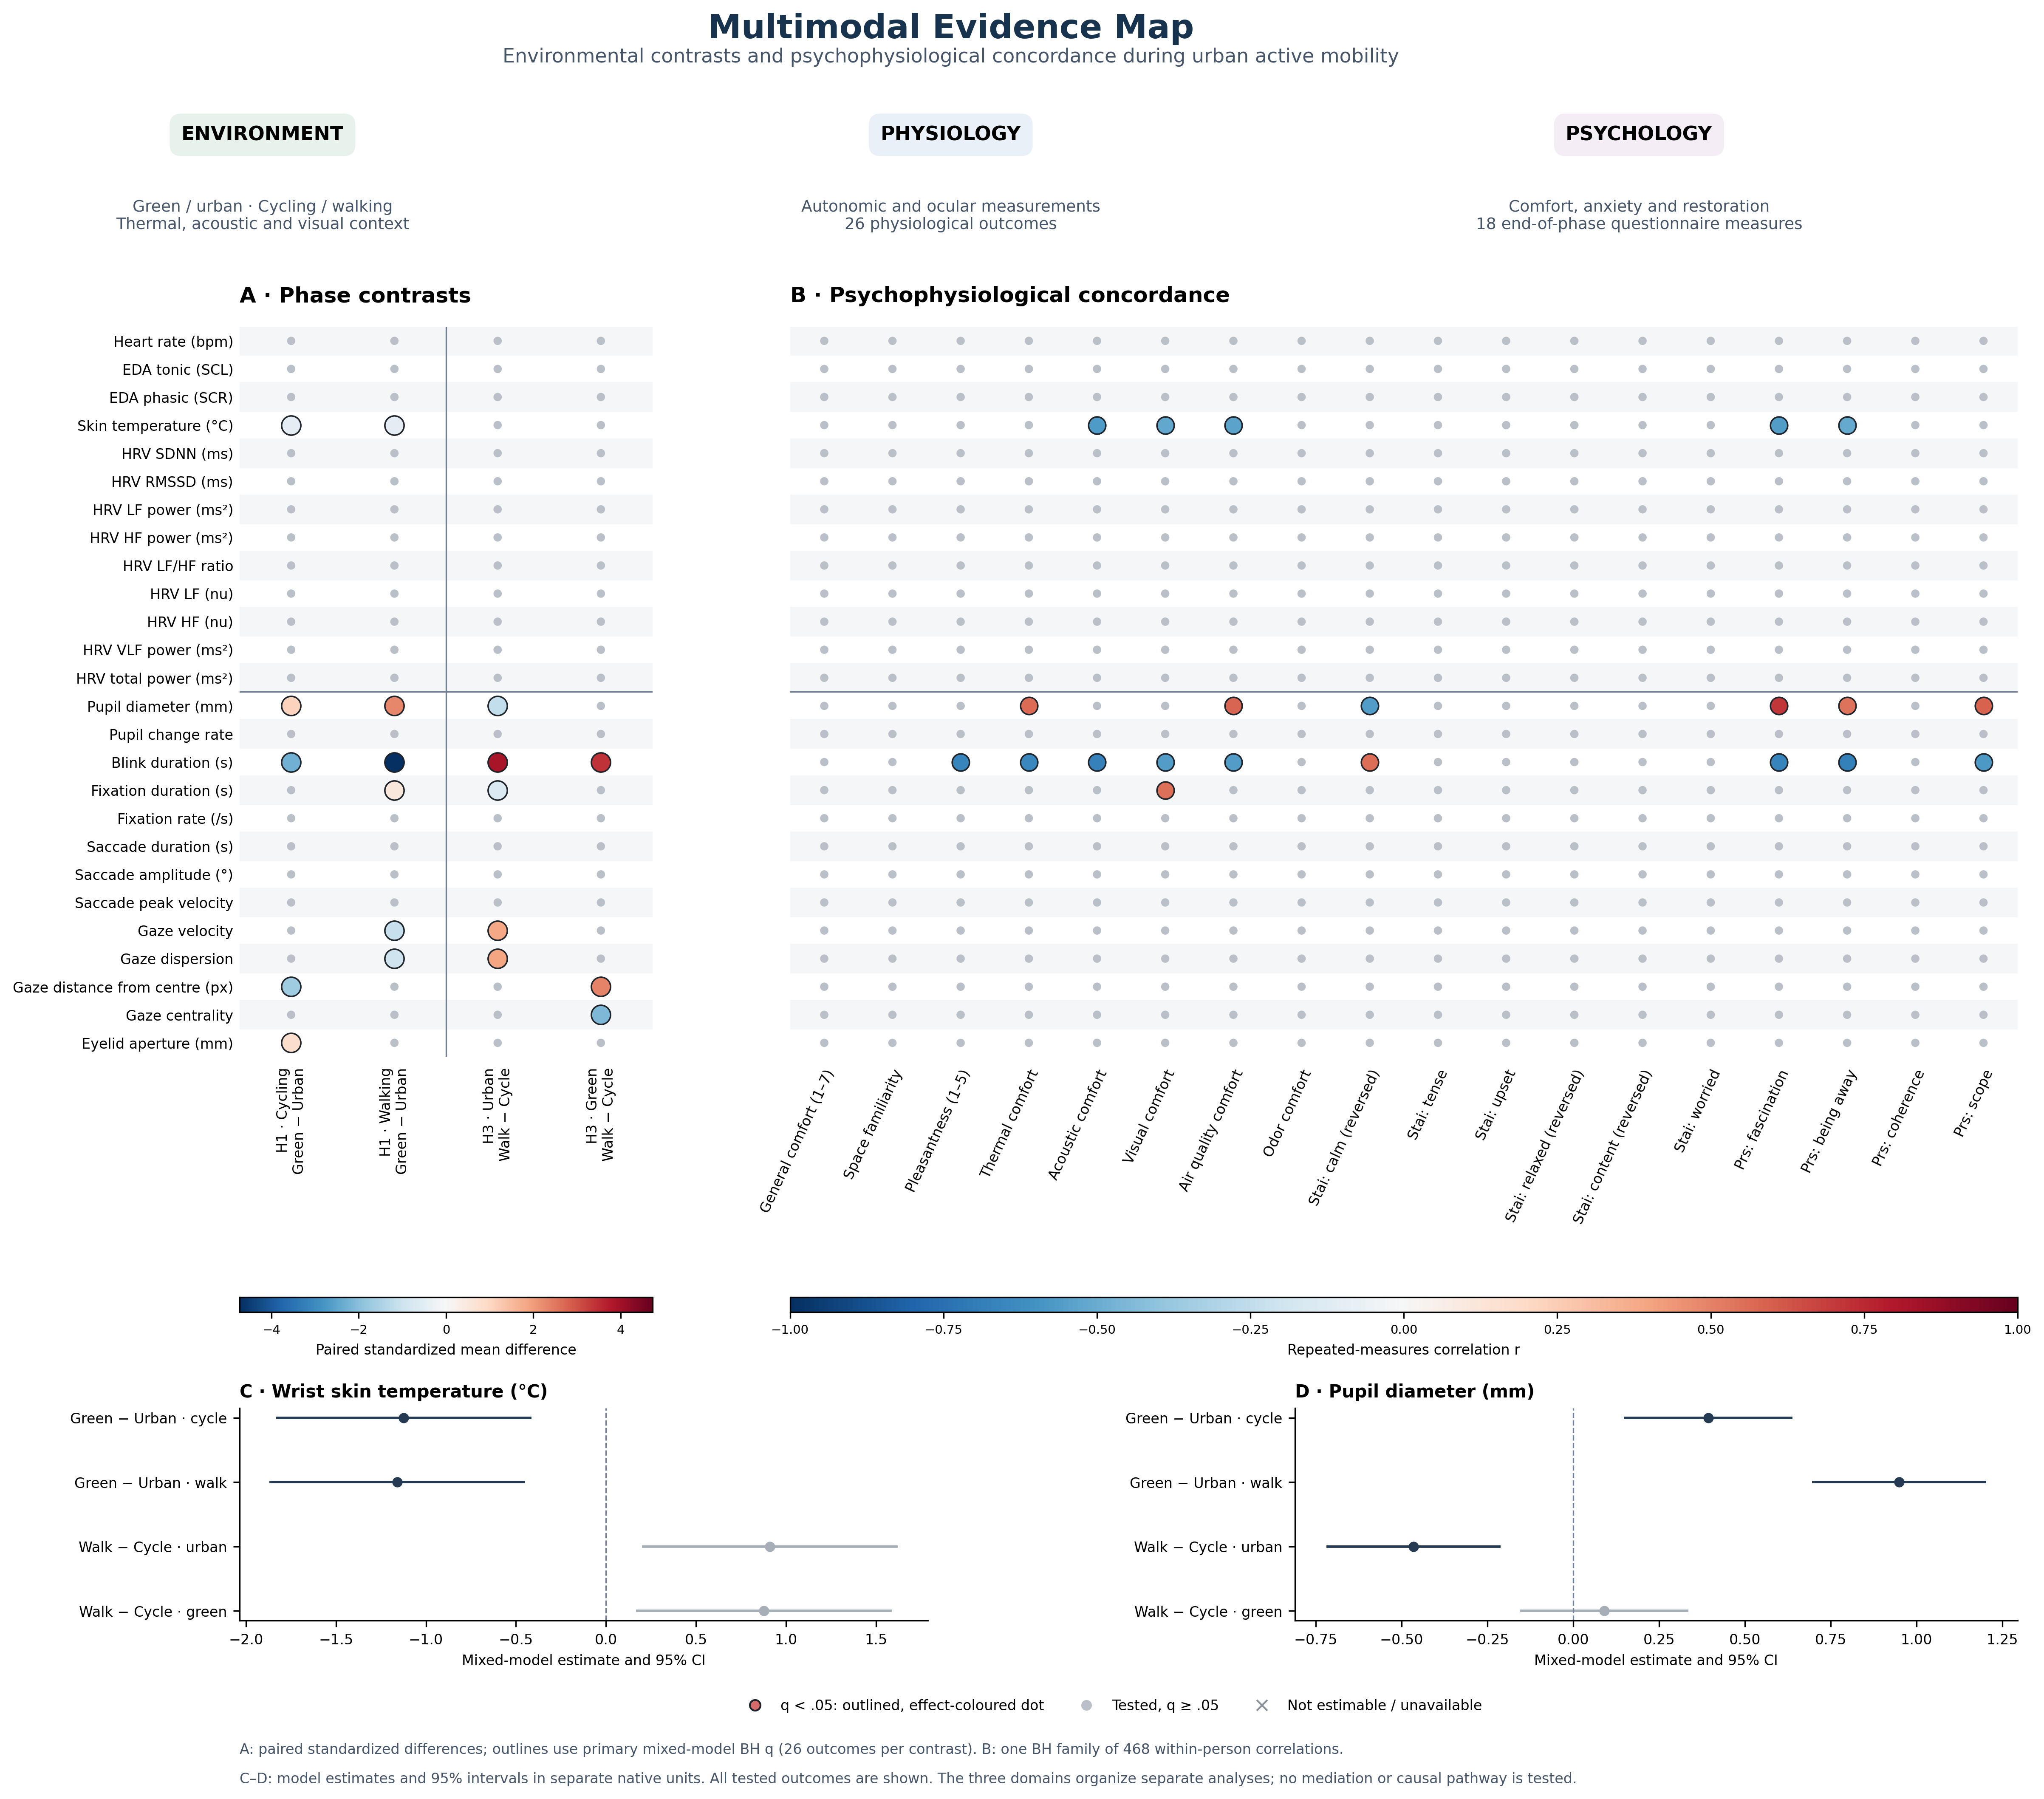

In [ ]:
# Figure 11: two maps, same layout, different grain. Circles = saved BH q < 0.05 only.
# Phase-average: H1_H3_Contrasts + H2_Concordance + H5_combined_phaseavg.
# 10 s: H1_H3_Planned_Contrasts_10s (phase_level) + H5_combined_timeseries. H2 has no 10 s table.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable


def fig11_evidence_map(grain='phaseavg'):
    assert grain in ('phaseavg', 'timeseries')
    root = Path(globals().get('ROOT', r'C:\Users\sanga\Desktop\Pranav Paper3_Final'))
    output = Path(globals().get('OUT', root / 'Figures'))
    res = root / 'output' / 'statistical_analysis' / 'results'
    outcomes = list(globals().get('OUTCOMES'))
    comparisons = ['BikeG - BikeU', 'WalkG - WalkU', 'WalkU - BikeU', 'WalkG - BikeG']
    contrast_cols = ['H1 cycling\ngreen minus urban', 'H1 walking\ngreen minus urban',
                     'H3 urban\nwalk minus cycle', 'H3 green\nwalk minus cycle']
    labels = globals().get('LAB', {})
    survey_labels = globals().get('SURVEY_LAB', {})
    label_overrides = {'eyetracker_gaze_velocity': 'Gaze velocity',
                       'eyetracker_saccade_peak_velocity': 'Saccade peak velocity'}

    def measure_label(name):
        return label_overrides.get(name, labels.get(name, name.replace('empatica_', '').replace('eyetracker_', '').replace('_', ' ')))

    def survey_label(name):
        if name in survey_labels:
            return survey_labels[name]
        text = name.removeprefix('questionnaire_')
        for suffix in ['_mean_1_5', '_1_5', '_1_7']:
            text = text.removesuffix(suffix)
        return text.replace('stai_', 'STAI: ').replace('prs11_', 'PRS: ').replace('_rev', ' (reversed)').replace('_', ' ').capitalize()

    def matrix(table, row, column, value, index, columns):
        return table.pivot(index=row, columns=column, values=value).reindex(index=index, columns=columns).to_numpy(float)

    if grain == 'phaseavg':
        contrasts_all = pd.read_csv(res / 'H1_H3_phaseavg' / 'H1_H3_Contrasts.csv')
        correlations = pd.read_csv(res / 'H1_H3_phaseavg' / 'H2_Concordance.csv')
        h5 = pd.read_csv(res / 'H5_combined_phaseavg' / 'H5_combined_phaseavg_Heat_Noise_Exposures.csv')
        hyp = contrasts_all['context'].str.extract(r'hypothesis=([^;]+)', expand=False).isin(['H1', 'H3'])
        primary = contrasts_all['scale'].str.startswith('normalization=Primary', na=False)
        contrasts = contrasts_all[hyp & primary & contrasts_all['context'].str.contains('outcome_type=Physiological', na=False)].copy()
        correlations = correlations[
            correlations['statistic_test'].eq('t-test (within-participant correlation)')
            & correlations['outcome'].str.startswith('questionnaire_', na=False)
        ].copy()
        questionnaires = correlations['outcome'].drop_duplicates().tolist()
        env_predictors = ['ucm_UTCI', 'ucm_AIR_T_mid', 'ucm_MRT', 'ucm_SND_dBA', 'SVF',
                          'atmo_pm2.5_avg', 'lys_lux_avg', 'lys_kelvin_avg']
        env_labels = ['UTCI', 'Air temp', 'MRT', 'Sound dBA', 'Sky view', 'PM2.5', 'Illuminance', 'Colour temp']
        assert len(contrasts) == 104 and len(correlations) == 468
        effects = matrix(contrasts, 'outcome', 'comparison', 'smd', outcomes, comparisons)
        contrast_q = matrix(contrasts, 'outcome', 'comparison', 'q_value', outcomes, comparisons)
        associations = matrix(correlations, 'predictor', 'outcome', 'correlation', outcomes, questionnaires)
        association_q = matrix(correlations, 'predictor', 'outcome', 'q_value', outcomes, questionnaires)
        show_b = True
        effect_norm = TwoSlopeNorm(vmin=-max(1., float(np.nanmax(np.abs(effects)))), vcenter=0,
                                   vmax=max(1., float(np.nanmax(np.abs(effects)))))
        env_clip = 1.0
        grain_title = 'Phase-average'
        a_bar = 'A: paired SMD  (red = negative, green = positive)'
        c_bar = 'C: coefficient per SD of env (clipped at ±1)'
        note = ('A: H1_H3_Contrasts.csv. B: H2_Concordance.csv (no 10 s table). '
                'C: H5_combined_phaseavg Heat_Noise_Exposures.csv, Eq1–7 unique hits.')
        b_kind = 'h2'
        b_title = 'B · Physiology with questionnaire'
        b_bar = 'B: correlation r  (red = negative, green = positive)'
        b_rotate = 65
        domains = [('ENVIRONMENT', 'C columns: measured env terms', '#e8f2ed'),
                   ('PHYSIOLOGY', 'Rows: 26 autonomic and ocular outcomes', '#eaf0f7'),
                   ('PSYCHOLOGY', 'B: 18 votes (phase-average only)', '#f4edf6')]
    else:
        raw = pd.read_csv(res / 'H1_H3_timeseries' / 'H1_H3_Planned_Contrasts_10s.csv')
        raw['hypothesis'] = raw['context'].str.extract(r'hypothesis=([^;]+)', expand=False)
        contrasts = raw[(raw['effect_type'] == 'phase_level') & raw['hypothesis'].isin(['H1', 'H3'])].copy()
        slopes = raw[(raw['effect_type'] == 'phase_slope') & raw['hypothesis'].isin(['H1', 'H3'])].copy()
        h5 = pd.read_csv(res / 'H5_combined_timeseries' / 'H5_combined_timeseries_hypothesis.csv')
        questionnaires = []
        env_predictors = ['ucm_UTCI', 'ucm_AIR_T_mid', 'ucm_MRT', 'ucm_HUMIDEX', 'ucm_SUN_Gh', 'SVF',
                          'gvi_50m', 'ucm_SND_dBA', 'atmo_pm2.5_avg', 'lys_lux_avg', 'lys_kelvin_avg']
        env_labels = ['UTCI', 'Air temp', 'MRT', 'HUMIDEX', 'Solar', 'Sky view', 'GVI',
                      'Sound dBA', 'PM2.5', 'Illuminance', 'Colour temp']
        assert len(contrasts) == 104 and len(slopes) == 104
        effects = matrix(contrasts, 'outcome', 'comparison', 'estimate', outcomes, comparisons)
        contrast_q = matrix(contrasts, 'outcome', 'comparison', 'q_value', outcomes, comparisons)
        associations = matrix(slopes, 'outcome', 'comparison', 'estimate', outcomes, comparisons)
        association_q = matrix(slopes, 'outcome', 'comparison', 'q_value', outcomes, comparisons)
        show_b = True
        finite = np.abs(effects[np.isfinite(effects)])
        effect_limit = max(1., float(np.nanmax(finite)) if finite.size else 1.)
        effect_norm = TwoSlopeNorm(vmin=-effect_limit, vcenter=0, vmax=effect_limit)
        slope_finite = np.abs(associations[np.isfinite(associations) & np.isfinite(association_q) & (association_q < .05)])
        slope_limit = float(np.nanmax(slope_finite)) if slope_finite.size else 1.
        correlation_norm = TwoSlopeNorm(vmin=-slope_limit, vcenter=0, vmax=slope_limit)
        env_clip = None
        grain_title = '10 s timeseries'
        a_bar = 'A: 10 s phase-level estimate (within-person z)'
        c_bar = 'C: t-statistic (estimate / SE); Y not standardized'
        b_bar = 'B: 10 s slope estimate (per minute, within-person z)'
        b_kind = 'slope'
        b_title = 'B · Phase slopes'
        b_rotate = 90
        note = ('A+B: H1_H3_Planned_Contrasts_10s.csv (level and slope). '
                'C: H5_combined_timeseries_hypothesis.csv, one circle per outcome × env (Eq1–7 unique; 26 BH rows collapse to 11).')
        domains = [('ENVIRONMENT', 'C columns: measured env terms', '#e8f2ed'),
                   ('PHYSIOLOGY LEVEL', 'A: 10 s phase-level contrasts', '#eaf0f7'),
                   ('PHYSIOLOGY SLOPE', 'B: 10 s per-minute slopes', '#f4edf6')]

    env_all = h5[~h5['predictor'].astype(str).str.startswith('Phase')].copy()
    env_hits = env_all[env_all['q_value'] < .05].sort_values('model_id').drop_duplicates(['outcome', 'predictor'])
    env = env_hits[env_hits['predictor'].isin(env_predictors)].copy()
    env['t_stat'] = pd.to_numeric(env['estimate'], errors='coerce') / pd.to_numeric(env['std_error'], errors='coerce')
    env_color_col = 't_stat' if grain == 'timeseries' else 'estimate'
    env_effects = matrix(env, 'outcome', 'predictor', env_color_col, outcomes, env_predictors)
    env_q = matrix(env, 'outcome', 'predictor', 'q_value', outcomes, env_predictors)
    if env_clip is None:
        hit = np.abs(env_effects[np.isfinite(env_q) & (env_q < .05)])
        vmax = float(np.nanmax(hit)) if hit.size else 1.
        vmax = vmax if np.isfinite(vmax) and vmax > 0 else 1.
        env_norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    else:
        env_norm = TwoSlopeNorm(vmin=-env_clip, vcenter=0, vmax=env_clip)
    if grain == 'phaseavg':
        correlation_norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    palette = LinearSegmentedColormap.from_list('neg_pos', ['#b91c1c', '#f8fafc', '#15803d'])

    figure = plt.figure(figsize=(18, 11.4), facecolor='white')
    if grain == 'phaseavg':
        phase_axis = figure.add_axes([.19, .28, .16, .50])
        env_axis = figure.add_axes([.36, .28, .20, .50], sharey=phase_axis)
        concordance_axis = figure.add_axes([.58, .28, .39, .50], sharey=phase_axis)
    else:
        phase_axis = figure.add_axes([.19, .28, .16, .50])
        concordance_axis = figure.add_axes([.36, .28, .16, .50], sharey=phase_axis)
        env_axis = figure.add_axes([.54, .28, .43, .50], sharey=phase_axis)

    def draw_hits(axis, values, adjusted_p, norm, column_labels, title, split=None):
        n_row = values.shape[0]
        for row in range(n_row):
            if row % 2 == 0:
                axis.axhspan(row - .5, row + .5, color='#f4f6f8', zorder=0)
            for column in range(values.shape[1]):
                value, q = values[row, column], adjusted_p[row, column]
                if np.isfinite(value) and np.isfinite(q) and q < .05:
                    mapped = value
                    if norm.vmin is not None and norm.vmax is not None:
                        mapped = np.clip(mapped, norm.vmin, norm.vmax)
                    axis.scatter(column, row, s=110 if values.shape[1] <= 8 else 88,
                                 color=palette(norm(mapped)), edgecolor='#20252b', linewidth=.85, zorder=3)
        axis.set(xlim=(-.5, values.shape[1] - .5), ylim=(n_row - .5, -.5))
        axis.set_xticks(range(len(column_labels)), column_labels)
        axis.tick_params(axis='x', length=0, labelsize=8, pad=6)
        axis.tick_params(axis='y', length=0, labelsize=8)
        axis.set_yticks(range(n_row))
        if split is not None:
            axis.axhline(split, color='#718096', linewidth=.8)
        axis.set_title(title, loc='left', fontsize=11, fontweight='bold', pad=12)
        for spine in axis.spines.values():
            spine.set_visible(False)

    draw_hits(phase_axis, effects, contrast_q, effect_norm, contrast_cols,
              'A · Phase contrasts', split=12.5)
    phase_axis.set_yticklabels([measure_label(name) for name in outcomes])
    phase_axis.axvline(1.5, color='#718096', linewidth=.8)
    plt.setp(phase_axis.get_xticklabels(), rotation=90, ha='right', va='center', rotation_mode='anchor')
    draw_hits(env_axis, env_effects, env_q, env_norm, env_labels,
              'C · Environment parameters', split=12.5)
    env_axis.tick_params(axis='y', labelleft=False)
    plt.setp(env_axis.get_xticklabels(), rotation=90, ha='right', va='center', rotation_mode='anchor')
    bars = [(phase_axis, effect_norm, a_bar), (env_axis, env_norm, c_bar)]
    if show_b:
        b_labels = contrast_cols if b_kind == 'slope' else [survey_label(name) for name in questionnaires]
        draw_hits(concordance_axis, associations, association_q, correlation_norm, b_labels, b_title, split=12.5)
        concordance_axis.tick_params(axis='y', labelleft=False)
        plt.setp(concordance_axis.get_xticklabels(), rotation=b_rotate, ha='right', va='center', rotation_mode='anchor')
        if b_kind == 'slope':
            concordance_axis.axvline(1.5, color='#718096', linewidth=.8)
        bars.append((concordance_axis, correlation_norm, b_bar))
    for axis, norm, label in bars:
        box = axis.get_position()
        color_axis = figure.add_axes([box.x0, .14, box.width, .01])
        colorbar = figure.colorbar(ScalarMappable(norm=norm, cmap=palette), cax=color_axis, orientation='horizontal')
        colorbar.set_label(label, fontsize=7)
        colorbar.ax.tick_params(labelsize=6.5)

    figure.suptitle(f'Multimodal Evidence Map · {grain_title}', y=.985, fontsize=19, fontweight='bold', color='#18334d')
    figure.text(.5, .955, 'Only BH q < 0.05 from the saved result tables is drawn. Blank cells were tested and were not significant.',
                ha='center', fontsize=11, color='#475569')
    for index, (heading, detail, color) in enumerate(domains):
        center = .20 + index * .30
        figure.text(center, .912, heading, ha='center', fontsize=11, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=.6', facecolor=color, edgecolor='none'))
        figure.text(center, .872, detail, ha='center', va='center', fontsize=9, color='#475569')
    handles = [Line2D([], [], marker='o', linestyle='', markerfacecolor='#15803d', markeredgecolor='#20252b', label='q < .05, positive'),
               Line2D([], [], marker='o', linestyle='', markerfacecolor='#b91c1c', markeredgecolor='#20252b', label='q < .05, negative')]
    figure.legend(handles=handles, loc='lower center', bbox_to_anchor=(.57, .07), ncol=2, frameon=False, fontsize=8)
    figure.text(.19, .045, note, fontsize=8, color='#475569')
    figure.text(.19, .025, 'Do not mix grains. Green = positive. Red = negative.', fontsize=8, color='#475569')
    output.mkdir(parents=True, exist_ok=True)
    stem = f'Figure11_multimodal_evidence_map_{grain}'
    figure.savefig(output / f'{stem}.svg', bbox_inches='tight', facecolor='white')
    figure.savefig(output / f'{stem}.png', dpi=300, bbox_inches='tight', facecolor='white')
    if grain == 'phaseavg':
        figure.savefig(output / 'Figure11_multimodal_evidence_map.svg', bbox_inches='tight', facecolor='white')
        figure.savefig(output / 'Figure11_multimodal_evidence_map.png', dpi=300, bbox_inches='tight', facecolor='white')
    counts = {'A': int((np.isfinite(contrast_q) & (contrast_q < .05)).sum()),
              'C': int((np.isfinite(env_q) & (env_q < .05)).sum())}
    if show_b:
        counts['B'] = int((association_q < .05).sum())
    print(f'{grain} BH q < 0.05 drawn: {counts}')
    try:
        from IPython.display import display
        display(figure)
    finally:
        plt.close(figure)
    return counts

fig11_evidence_map('phaseavg')
fig11_evidence_map('timeseries')


In [ ]:
# Figure 12 — Sound level bands per participant and phase
# Raw ucm_SND_dBA across 48 matched 10 s rows per participant and phase (no models)
# Grouped bar chart with 5 dBA bands: <55, 55-65, 65-70, 70-75, >=75
def fig12_sound():
    df = merged()
    p_order = ['P4', 'P8', 'P9', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P16', 'P17']
    bands = ['<55', '55-65', '65-70', '70-75', '>=75']

    def get_band(val):
        if val < 55: return '<55'
        elif val < 65: return '55-65'
        elif val < 70: return '65-70'
        elif val < 75: return '70-75'
        else: return '>=75'

    band_colors = {'<55': '#2B6CB0', '55-65': '#90CDF4', '65-70': '#FEFCBF', '70-75': '#F6AD55', '>=75': '#C53030'}
    band_edge_colors = {'<55': '#1A365D', '55-65': '#3182CE', '65-70': '#D69E2E', '70-75': '#DD6B20', '>=75': '#742A2A'}

    fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), dpi=300, sharex=True, sharey=True)
    plt.subplots_adjust(left=0.06, right=0.92, top=0.90, bottom=0.08, hspace=0.20, wspace=0.06)

    phase_configs = [
        ('WalkU', axes[0, 0]),
        ('BikeU', axes[0, 1]),
        ('WalkG', axes[1, 0]),
        ('BikeG', axes[1, 1])
    ]

    for phase, ax in phase_configs:
        sub = df[df['PhaseID'] == phase].copy()
        median_val = sub['ucm_SND_dBA'].median()
        pct_ge70 = (sub['ucm_SND_dBA'] >= 70).mean() * 100
        pct_lt55 = (sub['ucm_SND_dBA'] < 55).mean() * 100

        ax.set_title(f"{phase} (median {median_val:.1f} dBA; ≥70: {pct_ge70:.0f}%, <55: {pct_lt55:.0f}%)",
                     fontsize=10.5, fontweight='normal', pad=6)

        sub['band'] = sub['ucm_SND_dBA'].apply(get_band)
        ct = pd.crosstab(sub['ParticipantID'], sub['band']).reindex(index=p_order, columns=bands).fillna(0).astype(int)

        n_groups = len(p_order)
        bar_width = 0.15
        x_indices = np.arange(n_groups)

        for b_idx, band in enumerate(bands):
            offsets = (b_idx - 2) * bar_width
            values = ct[band].values
            bars = ax.bar(x_indices + offsets, values, width=bar_width,
                          color=band_colors[band], edgecolor=band_edge_colors[band],
                          linewidth=0.6, label=band if phase == 'BikeU' else "")

            for bar, val in zip(bars, values):
                if val > 0:
                    ax.text(bar.get_x() + bar.get_width() / 2.0, val + 0.6,
                            f"{val}", ha='center', va='bottom', fontsize=6.5, color='#222222')

        for x in x_indices[:-1]:
            ax.axvline(x + 0.5, color='#E2E8F0', linestyle='-', linewidth=0.8, zorder=0)

        ax.set_ylim(0, 52)
        ax.set_yticks([0, 10, 20, 30, 40, 50])
        ax.tick_params(axis='both', which='major', labelsize=9)

    for ax in [axes[1, 0], axes[1, 1]]:
        ax.set_xticks(np.arange(len(p_order)))
        ax.set_xticklabels(p_order, fontsize=9.5)

    axes[0, 0].set_ylabel('Number of 10 s rows (of 48)', fontsize=10)
    axes[1, 0].set_ylabel('Number of 10 s rows (of 48)', fontsize=10)

    handles, labels = axes[0, 1].get_legend_handles_labels()
    fig.legend(handles, labels, title='dBA band', loc='center left', bbox_to_anchor=(0.93, 0.72),
               frameon=True, edgecolor='#A0AEC0', fontsize=8.5, title_fontsize=9.0)

    fig.suptitle('Sound level bands per participant and phase (raw ucm_SND_dBA, 48 matched 10 s rows each, no models)',
                 fontsize=11.5, fontweight='normal', y=0.97)

    save(fig, "Figure12_sound_level_bands")

fig12_sound()


In [ ]:
# Figure 13A/B — YAMNet majority counts and summed proportions
# Same grouped-bar 2x2 as Figure 12 (WalkU, BikeU, WalkG, BikeG; 11 people; 48 matched 10 s rows).
# 13A: stored `category` (NA coded Unidentify). 13B: ignore majority; sum each *_proportion.
def _yamnet_label_style():
    labels = [
        'Rural/Natural', 'Wind', 'Vehicle', 'Urban/Manmade_positive',
        'Urban/Manmade_neutral', 'Urban/Manmade_negative', 'Mechanisms', 'Unidentify',
    ]
    pretty = {
        'Rural/Natural': 'Rural / natural', 'Wind': 'Wind', 'Vehicle': 'Vehicle',
        'Urban/Manmade_positive': 'Urban / man-made +', 'Urban/Manmade_neutral': 'Urban / man-made 0',
        'Urban/Manmade_negative': 'Urban / man-made −', 'Mechanisms': 'Mechanisms',
        'Unidentify': 'Unidentified',
    }
    colors = {
        'Rural/Natural': '#2F855A', 'Wind': '#3182CE', 'Vehicle': '#C53030',
        'Urban/Manmade_positive': '#D69E2E', 'Urban/Manmade_neutral': '#718096',
        'Urban/Manmade_negative': '#6B46C1', 'Mechanisms': '#9C4221', 'Unidentify': '#A0AEC0',
    }
    edges = {
        'Rural/Natural': '#1C4532', 'Wind': '#2A4365', 'Vehicle': '#742A2A',
        'Urban/Manmade_positive': '#744210', 'Urban/Manmade_neutral': '#2D3748',
        'Urban/Manmade_negative': '#44337A', 'Mechanisms': '#652B19', 'Unidentify': '#4A5568',
    }
    prop_col = {
        'Rural/Natural': 'rural_natural_proportion', 'Wind': 'wind_proportion',
        'Vehicle': 'vehicle_proportion', 'Urban/Manmade_positive': 'urban_manmade_positive_proportion',
        'Urban/Manmade_neutral': 'urban_manmade_neutral_proportion',
        'Urban/Manmade_negative': 'urban_manmade_negative_proportion',
        'Mechanisms': 'mechanisms_proportion', 'Unidentify': 'unidentify_proportion',
    }
    return labels, pretty, colors, edges, prop_col

def _yamnet_grouped_bars(ax, matrix, labels, pretty, colors, edges, annotate, legend, min_label,
                         ylim=(0, 52), yticks=(0, 10, 20, 30, 40, 50), bottom=0.0, y_nudge=(0.45, 1.55)):
    n_labs = len(labels)
    bar_width = 0.10
    x = np.arange(matrix.shape[0])
    for i, lab in enumerate(labels):
        offsets = (i - (n_labs - 1) / 2.0) * bar_width
        values = matrix[lab].to_numpy(dtype=float)
        heights = np.where(np.isfinite(values), values - bottom, 0.0)
        bars = ax.bar(x + offsets, heights, width=bar_width, bottom=bottom,
                      color=colors[lab], edgecolor=edges[lab], linewidth=0.6,
                      label=pretty[lab] if legend else "")
        nudge = y_nudge[0] if i % 2 == 0 else y_nudge[1]
        for bar, val in zip(bars, values):
            if np.isfinite(val) and val >= min_label:
                ax.text(bar.get_x() + bar.get_width() / 2.0, val + nudge, annotate(val),
                        ha='center', va='bottom', fontsize=6.0, color='#222222')
    for xi in x[:-1]:
        ax.axvline(xi + 0.5, color='#E2E8F0', linestyle='-', linewidth=0.8, zorder=0)
    ax.set_ylim(*ylim)
    ax.set_yticks(list(yticks))
    ax.tick_params(axis='both', which='major', labelsize=9)

def _yamnet_finish(fig, axes, p_order, ylabel, legend_title, suptitle, name):
    for ax in [axes[1, 0], axes[1, 1]]:
        ax.set_xticks(np.arange(len(p_order)))
        ax.set_xticklabels(p_order, fontsize=9.5)
    axes[0, 0].set_ylabel(ylabel, fontsize=10)
    axes[1, 0].set_ylabel(ylabel, fontsize=10)
    handles, legend_labels = axes[0, 1].get_legend_handles_labels()
    fig.legend(handles, legend_labels, title=legend_title, loc='center left',
               bbox_to_anchor=(0.93, 0.55), frameon=True, edgecolor='#A0AEC0',
               fontsize=8.5, title_fontsize=9.0)
    fig.suptitle(suptitle, fontsize=11.5, fontweight='normal', y=0.97)
    save(fig, name)

def fig13_a_yamnet():
    df = merged().copy()
    p_order = ['P4', 'P8', 'P9', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P16', 'P17']
    labels, pretty, colors, edges, _prop_col = _yamnet_label_style()
    df['yamnet_majority'] = df['category'].where(df['category'].notna(), 'Unidentify')
    fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), dpi=300, sharex=True, sharey=True)
    plt.subplots_adjust(left=0.06, right=0.92, top=0.90, bottom=0.08, hspace=0.20, wspace=0.06)
    for phase, ax in zip(['WalkU', 'BikeU', 'WalkG', 'BikeG'],
                         [axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]]):
        sub = df[df['PhaseID'] == phase]
        ct = (pd.crosstab(sub['ParticipantID'], sub['yamnet_majority'])
              .reindex(index=p_order, columns=labels).fillna(0).astype(int))
        share = sub['yamnet_majority'].value_counts(normalize=True)
        top_lab = pretty.get(share.index[0], share.index[0])
        rural_pct = (sub['yamnet_majority'] == 'Rural/Natural').mean() * 100
        veh_pct = (sub['yamnet_majority'] == 'Vehicle').mean() * 100
        ax.set_title(
            f"{phase} (majority {top_lab}: {share.iloc[0]*100:.0f}%; rural {rural_pct:.0f}%; vehicle {veh_pct:.0f}%)",
            fontsize=10.5, pad=6)
        _yamnet_grouped_bars(ax, ct, labels, pretty, colors, edges,
                             lambda v: f"{int(round(v))}", legend=(phase == 'BikeU'), min_label=4)
    _yamnet_finish(
        fig, axes, p_order, 'Number of 10 s rows (of 48)', 'YAMNet majority',
        'Figure 13A. YAMNet majority label per participant and phase (one stored category per 10 s row, 48 matched rows each, no models)',
        'Figure13_A_yamnet_majority')

def fig13_b_yamnet():
    df = merged().copy()
    p_order = ['P4', 'P8', 'P9', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P16', 'P17']
    labels, pretty, colors, edges, prop_col = _yamnet_label_style()
    for col in prop_col.values():
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0.0)
    fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), dpi=300, sharex=True, sharey=True)
    plt.subplots_adjust(left=0.06, right=0.92, top=0.90, bottom=0.08, hspace=0.20, wspace=0.06)
    for phase, ax in zip(['WalkU', 'BikeU', 'WalkG', 'BikeG'],
                         [axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]]):
        sub = df[df['PhaseID'] == phase]
        sums = (sub.groupby('ParticipantID')[list(prop_col.values())].sum()
                .reindex(index=p_order).fillna(0.0))
        sums.columns = list(prop_col.keys())
        mean_prop = sub[list(prop_col.values())].mean()
        top_key = mean_prop.idxmax()
        top_name = pretty[next(k for k, col in prop_col.items() if col == top_key)]
        ax.set_title(
            f"{phase} (mean {top_name}: {mean_prop[top_key]*100:.0f}%; rural {mean_prop['rural_natural_proportion']*100:.0f}%; vehicle {mean_prop['vehicle_proportion']*100:.0f}%)",
            fontsize=10.5, pad=6)
        _yamnet_grouped_bars(ax, sums, labels, pretty, colors, edges,
                             lambda v: f"{v:.0f}" if abs(v - round(v)) < 0.05 else f"{v:.1f}",
                             legend=(phase == 'BikeU'), min_label=6)
    _yamnet_finish(
        fig, axes, p_order, 'Sum of 10 s proportions', 'YAMNet proportion',
        'Figure 13B. YAMNet proportions summed across 48 rows per participant and phase (majority ignored, no models)',
        'Figure13_B_yamnet_proportions')


fig13_a_yamnet()
fig13_b_yamnet()


In [ ]:
html = ["<!DOCTYPE html><html><head><meta charset='utf-8'><title>Paper 3 Figures</title></head>",
        "<body style='text-align:center;font-family:sans-serif;background-color:#F8F9FA;padding:20px;'>",
        "<h1>Paper 3: All Publication Figures (Figure 1 to 13 & Literature Series)</h1><hr>"]

# Grouped figure list in presentation order
fig_order = [
    "Figure1_styled_map", "Figure5_exposures_by_phase", "Figure6_H1_forest", "Figure7_H3_forest",
    "Figure8_H2_rmcorr", "Figure9_sound_composition", "Figure10_outcomes_by_phase",
    "Figure11_Stimulus Organism Response fdr", "Figure12_sound_level_bands",
    "Figure13_A_yamnet_majority",
    "Figure13_B_yamnet_proportions",
    "literature_fig1_spatial_transect", "literature_fig2_multisystem_network",
    "literature_fig3_bivariate_coexposure", "literature_fig4_visual_attention_art", "test_A"
]

for name in fig_order:
    svg_f = OUT / f"{name}.svg"
    png_f = OUT / f"{name}.png"
    target = svg_f if svg_f.exists() else (png_f if png_f.exists() else None)
    if target:
        html += [f"<div style='margin:30px auto;padding:20px;background:white;border-radius:8px;box-shadow:0 2px 8px rgba(0,0,0,0.1);max-width:1200px;'>",
                 f"<h2 style='color:#1A237E;'>{target.name}</h2>",
                 f"<img src='{target.name}' style='max-width:100%;height:auto;'>",
                 f"</div>"]

html += ["</body></html>"]
html_path = OUT / "all_figures.html"
html_path.write_text("\n".join(html), encoding="utf-8")
print("Saved comprehensive HTML viewer:", html_path)


In [ ]:
# H4 context: 11 participants, acoustic comfort (bar) + dBA (box); thermal comfort (box) + UTCI (bar).
import sys
from pathlib import Path
sys.path.insert(0, str(Path(ROOT) / 'scripts') if 'ROOT' in dir() else '.')
from h4_participant_exposure_votes import draw
draw()
